In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

In [2]:
# If needed:
# %pip install requests pandas numpy openpyxl

from pathlib import Path
from datetime import datetime
from shutil import copy2
import json
import os

import requests
import numpy as np
import pandas as pd
from openpyxl import load_workbook


# 1. Configuration
SEASON = "Monsoon"
LATITUDE = 23.0031
LONGITUDE = 71.3923
LOCAL_TIMEZONE = "Asia/Kolkata"
DNI_COLUMN = "OM-DNI (W/m2)"

DATA_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
    r"\OneDrive_2026-08-26\Solar Profile Dataset\Monsoon"
)

FILES = {
    "Train": DATA_DIR / "Monsoon_Train.xlsx",
    "Validation": DATA_DIR / "Monsoon_Val.xlsx",
    "Test": DATA_DIR / "Monsoon_Test.xlsx",
}

EXPECTED_RANGES = {
    "Train": ("2025-06-15", "2025-09-08"),
    "Validation": ("2025-09-09", "2025-10-07"),
    "Test": ("2025-10-08", "2025-10-14"),
}

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
backup_dir = DATA_DIR / "Backups" / f"Before_DNI_{run_id}"
dni_dir = DATA_DIR / "OpenMeteo_DNI"

workbooks = {}
sheets = {}
timestamps_by_split = {}
drift_report = {}


# 2. Read and validate the manually split files.
# Timestamp rounding is used for DNI matching only.
# Existing Excel timestamps and other cell values are left unchanged.
try:
    for split, path in FILES.items():
        if not path.is_file():
            raise FileNotFoundError(path)

        workbook = load_workbook(path)
        workbooks[split] = workbook

        sheet = workbook.worksheets[0]
        sheets[split] = sheet
        headers = [cell.value for cell in sheet[1]]

        if headers.count("TimeStamp") != 1:
            raise ValueError(f"{path.name}: expected one TimeStamp column.")

        if headers.count(DNI_COLUMN) > 1:
            raise ValueError(f"{path.name}: duplicate DNI columns.")

        time_column = headers.index("TimeStamp") + 1
        original_times = pd.DatetimeIndex(pd.to_datetime(
            [
                sheet.cell(row, time_column).value
                for row in range(2, sheet.max_row + 1)
            ],
            errors="raise",
        ))

        if original_times.empty or original_times.hasnans:
            raise ValueError(f"{path.name}: empty or missing timestamps.")

        if original_times.tz is not None:
            raise ValueError(
                f"{path.name}: expected timezone-naive local IST timestamps."
            )

        # Handle the previously verified Monsoon drift, at most 8.735 s.
        times = original_times.round("15min")
        adjustments = np.abs(
            (times - original_times).total_seconds()
        )

        if adjustments.max() > 10.0:
            raise ValueError(
                f"{path.name}: timestamp drift exceeds 10 seconds."
            )

        if times.has_duplicates:
            raise ValueError(
                f"{path.name}: duplicate timestamps after rounding."
            )

        start, end = EXPECTED_RANGES[split]
        expected = pd.date_range(
            start,
            pd.Timestamp(end) + pd.Timedelta(hours=23, minutes=45),
            freq="15min",
        )

        if not times.sort_values().equals(expected):
            raise ValueError(
                f"{path.name}: expected {start} through {end}, "
                f"{len(expected):,} rows; found {len(times):,}.\n"
                f"Missing blocks: {expected.difference(times)[:5].tolist()}\n"
                f"Unexpected blocks: {times.difference(expected)[:5].tolist()}"
            )

        # Retain original row order for writing DNI to the correct cells.
        timestamps_by_split[split] = times
        drift_report[split] = {
            "rounded_for_matching": int(np.count_nonzero(adjustments)),
            "maximum_adjustment_seconds": float(adjustments.max()),
        }

        print(
            f"{split}: validated {len(times):,} rows | "
            f"{start} through {end}"
        )

    # 3. Download hourly historical DNI in UTC.
    # Extra boundary days cover timezone conversion and hourly intervals.
    params = {
        "latitude": LATITUDE,
        "longitude": LONGITUDE,
        "start_date": "2025-06-14",
        "end_date": "2025-10-15",
        "hourly": "direct_normal_irradiance",
        "models": "era5",
        "timezone": "UTC",
    }

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=params,
        timeout=180,
    )
    response.raise_for_status()
    payload = response.json()

    if payload.get("error"):
        raise RuntimeError(payload.get("reason", "Open-Meteo API error."))

    hourly = payload.get("hourly", {})
    if (
        "time" not in hourly
        or "direct_normal_irradiance" not in hourly
    ):
        raise ValueError("API response is missing hourly DNI data.")

    hourly_end_utc = pd.DatetimeIndex(
        pd.to_datetime(hourly["time"], utc=True, errors="raise")
    )
    hourly_values = np.asarray(
        hourly["direct_normal_irradiance"],
        dtype=np.float64,
    )

    if (
        len(hourly_end_utc) < 2
        or hourly_end_utc.hasnans
        or hourly_values.shape != (len(hourly_end_utc),)
        or not np.isfinite(hourly_values).all()
        or np.any(hourly_values < 0)
    ):
        raise ValueError("API returned invalid or missing DNI.")

    if (
        hourly_end_utc.has_duplicates
        or not hourly_end_utc.is_monotonic_increasing
        or not np.all(
            np.diff(hourly_end_utc.asi8)
            == pd.Timedelta(hours=1).value
        )
    ):
        raise ValueError("API hourly timestamps are not continuous.")

    # Each value describes [timestamp - 1 hour, timestamp).
    hourly_start_local = (
        (hourly_end_utc - pd.Timedelta(hours=1))
        .tz_convert(LOCAL_TIMEZONE)
        .tz_localize(None)
    )

    # 4. Map each 15-minute block to its containing hourly interval.
    # This repeats hourly means; it does not create measured 15-minute DNI.
    mapped_values = {}

    for split, times in timestamps_by_split.items():
        positions = hourly_start_local.get_indexer(times, method="pad")

        if np.any(positions < 0):
            raise ValueError(f"{split}: DNI starts after the first block.")

        interval_starts = hourly_start_local[positions]
        interval_ends = interval_starts + pd.Timedelta(hours=1)
        block_ends = times + pd.Timedelta(minutes=15)

        if (
            np.any(times < interval_starts)
            or np.any(block_ends > interval_ends)
        ):
            raise ValueError(
                f"{split}: a block is outside its hourly DNI interval."
            )

        mapped_values[split] = hourly_values[positions]

    # Preserve request, response, and alignment details.
    dni_dir.mkdir(parents=True, exist_ok=True)
    api_path = dni_dir / f"{SEASON}_DNI_API_{run_id}.json"

    with api_path.open("w", encoding="utf-8") as handle:
        json.dump(
            {
                "request": params,
                "response": payload,
                "mapping": (
                    "Preceding-hour mean assigned to contained "
                    "15-minute block-start intervals"
                ),
                "local_timezone": LOCAL_TIMEZONE,
                "timestamp_drift": drift_report,
                "excel_timestamps_modified": False,
            },
            handle,
            indent=2,
        )

    # 5. Back up all originals before staging replacements.
    backup_dir.mkdir(parents=True, exist_ok=False)
    for path in FILES.values():
        copy2(path, backup_dir / path.name)

    # 6. Stage all updated workbooks before replacing any original.
    staged_paths = {}

    for split, path in FILES.items():
        workbook = workbooks[split]
        sheet = sheets[split]
        headers = [cell.value for cell in sheet[1]]

        if DNI_COLUMN in headers:
            dni_column_index = headers.index(DNI_COLUMN) + 1
        else:
            dni_column_index = sheet.max_column + 1
            sheet.cell(1, dni_column_index, DNI_COLUMN)

        for row, value in enumerate(mapped_values[split], start=2):
            sheet.cell(row, dni_column_index, float(value))

        staged_path = path.with_name(
            f"{path.stem}_DNI_pending_{run_id}.xlsx"
        )
        workbook.save(staged_path)
        staged_paths[split] = staged_path

finally:
    for workbook in workbooks.values():
        workbook.close()


# 7. Replace originals and overwrite the matching DNI CSVs.
# If Excel blocks a replacement, close Excel and rerun this function only.
def finish_dni_update():
    for split, path in FILES.items():
        staged_path = staged_paths[split]

        if staged_path.exists():
            try:
                os.replace(staged_path, path)
            except PermissionError:
                raise PermissionError(
                    f"Close {path.name} in Excel, then run "
                    "finish_dni_update(). Earlier files may already "
                    f"be updated. Backups: {backup_dir}"
                ) from None

        dni_frame = pd.DataFrame({
            "TimeStamp": timestamps_by_split[split],
            DNI_COLUMN: mapped_values[split],
        }).sort_values("TimeStamp", ignore_index=True)

        csv_path = dni_dir / f"{SEASON}_{split}_DNI.csv"
        pending_csv = dni_dir / f"{SEASON}_{split}_DNI_pending.csv"

        dni_frame.to_csv(
            pending_csv,
            index=False,
            date_format="%Y-%m-%d %H:%M",
        )

        try:
            os.replace(pending_csv, csv_path)
        except PermissionError:
            raise PermissionError(
                f"Close {csv_path.name} in Excel, then run "
                "finish_dni_update(). The Excel update has already "
                "completed for this split."
            ) from None

        print(f"\n{split}: added/replaced DNI for {len(dni_frame):,} rows")
        print(f"  Excel: {path}")
        print(f"  CSV:   {csv_path}")

    print(f"\nOriginal backups: {backup_dir}")
    print(f"API record: {api_path}")
    print("Manual train/validation/test splits preserved.")
    print("Existing Excel timestamps were not changed.")
    print("\nReload train, validation, test and test_with_history before S4.")


finish_dni_update()

Train: validated 8,256 rows | 2025-06-15 through 2025-09-08
Validation: validated 2,784 rows | 2025-09-09 through 2025-10-07
Test: validated 672 rows | 2025-10-08 through 2025-10-14

Train: added/replaced DNI for 8,256 rows
  Excel: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Monsoon\Monsoon_Train.xlsx
  CSV:   C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Monsoon\OpenMeteo_DNI\Monsoon_Train_DNI.csv

Validation: added/replaced DNI for 2,784 rows
  Excel: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Monsoon\Monsoon_Val.xlsx
  CSV:   C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Monsoon\OpenMeteo_DNI\Monsoon_Validation_DNI.csv

Test: added/replaced DNI for 672 rows
  Excel: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Monsoon\Monsoon_Test.xlsx
  CSV:   C:\Users\yashs\Desktop\ML\Project F

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd

SEASON = "Monsoon"
SCENARIO = "S4"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
DATA_DIR = (
    PROJECT_DIR
    / "OneDrive_2026-08-26"
    / "Solar Profile Dataset"
    / SEASON
)

TRAIN_PATH = DATA_DIR / "Monsoon_Train.xlsx"
VALIDATION_PATH = DATA_DIR / "Monsoon_Val.xlsx"
TEST_PATH = DATA_DIR / "Monsoon_Test.xlsx"

TEST_START = pd.Timestamp("2025-10-08")
TEST_END_EXCLUSIVE = pd.Timestamp("2025-10-15")
HISTORY_DAY = TEST_START - pd.Timedelta(days=1)

POWER_COLUMN = "Act. Power (MW)"

PAST_EXOG_COLUMNS = [
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
]
HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS

SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]
FUTURE_EXOG_COLUMNS = SELECTED_FUTURE_EXOG_COLUMNS.copy()

required_columns = [
    "TimeStamp",
    *dict.fromkeys(HISTORY_COLUMNS + FUTURE_EXOG_COLUMNS),
]


def load_split(path, split_name, first_day, last_day):
    """Read, standardize and validate one manually split Excel file."""
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"Dataset not found: {path}")

    data = pd.read_excel(path)

    if data.empty:
        raise ValueError(f"{split_name}: empty dataset.")

    def normalize(name):
        return " ".join(str(name).split())

    lookup = {}
    for column in data.columns:
        lookup.setdefault(normalize(column), []).append(column)

    rename_map = {}
    for required in required_columns:
        matches = lookup.get(normalize(required), [])

        if not matches:
            raise ValueError(
                f"{split_name}: missing required column {required!r}.\n"
                f"Available columns: {data.columns.tolist()}"
            )

        if len(matches) != 1:
            raise ValueError(
                f"{split_name}: ambiguous columns for {required!r}: {matches}"
            )

        rename_map[matches[0]] = required

    data = data.rename(columns=rename_map)

    timestamps = pd.to_datetime(
        data["TimeStamp"], errors="raise"
    )

    if timestamps.isna().any():
        raise ValueError(f"{split_name}: missing timestamps.")

    if timestamps.dt.tz is not None:
        raise ValueError(
            f"{split_name}: expected timezone-naive local IST timestamps."
        )

    # Correct the previously verified small timestamp drift in memory.
    # No Excel cells or split assignments are changed.
    corrected_times = timestamps.dt.round("15min")
    adjustments = (
        corrected_times - timestamps
    ).abs().dt.total_seconds()

    if adjustments.max() > 10.0:
        raise ValueError(
            f"{split_name}: timestamp drift exceeds 10 seconds. "
            "Inspect the source timestamps."
        )

    if corrected_times.duplicated().any():
        raise ValueError(
            f"{split_name}: duplicate timestamps after rounding."
        )

    data["TimeStamp"] = corrected_times
    data = data.sort_values("TimeStamp").reset_index(drop=True)
    data["Date"] = data["TimeStamp"].dt.date

    expected = pd.date_range(
        first_day,
        pd.Timestamp(last_day) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )
    observed = pd.DatetimeIndex(data["TimeStamp"])

    if not observed.equals(expected):
        raise ValueError(
            f"{split_name}: expected {first_day} through {last_day}, "
            f"with {len(expected):,} rows; found {len(data):,}.\n"
            f"Missing blocks: {expected.difference(observed)[:5].tolist()}\n"
            f"Unexpected blocks: {observed.difference(expected)[:5].tolist()}"
        )

    for column in required_columns[1:]:
        data[column] = pd.to_numeric(data[column], errors="raise")

    if not np.isfinite(
        data[required_columns[1:]].to_numpy(dtype=np.float64)
    ).all():
        raise ValueError(
            f"{split_name}: required measurements contain "
            "missing or infinite values."
        )

    if data["OM-DNI (W/m2)"].lt(0).any():
        raise ValueError(f"{split_name}: negative DNI values found.")

    print(
        f"{split_name}: {data['Date'].nunique()} days | "
        f"{len(data):,} rows | {observed[0]} → {observed[-1]}"
    )

    corrected_count = int((adjustments > 0).sum())
    if corrected_count:
        print(
            f"  Rounded {corrected_count:,} timestamps in memory; "
            f"maximum adjustment {adjustments.max():.3f} seconds."
        )

    return data


# Load the files directly—no prior train/validation/test variables needed.
train = load_split(
    TRAIN_PATH, "Training", "2025-06-15", "2025-09-08"
)
validation = load_split(
    VALIDATION_PATH, "Validation", "2025-09-09", "2025-10-07"
)
test = load_split(
    TEST_PATH, "Test targets", "2025-10-08", "2025-10-14"
)

# Copy October 7 for input history only.
history_rows = validation.loc[
    validation["Date"].eq(HISTORY_DAY.date())
].copy()

sample_columns = [*required_columns, "Date"]

test_with_history = pd.concat(
    [
        history_rows.loc[:, sample_columns],
        test.loc[:, sample_columns],
    ],
    ignore_index=True,
).sort_values("TimeStamp", ignore_index=True)

expected_history_grid = pd.date_range(
    HISTORY_DAY, periods=8 * 96, freq="15min"
)
if not pd.DatetimeIndex(
    test_with_history["TimeStamp"]
).equals(expected_history_grid):
    raise ValueError("Incomplete October 7–14 test-with-history grid.")

print("\nMonsoon S4 data loaded, including DNI.")
print(f"Test including history: {len(test_with_history):,} rows")
print("Expected samples: Training 340 | Validation 112 | Test 28")
print("Manual splits preserved. Excel files unchanged.")

Training: 86 days | 8,256 rows | 2025-06-15 00:00:00 → 2025-09-08 23:45:00
  Rounded 1,746 timestamps in memory; maximum adjustment 8.735 seconds.
Validation: 29 days | 2,784 rows | 2025-09-09 00:00:00 → 2025-10-07 23:45:00
Test targets: 7 days | 672 rows | 2025-10-08 00:00:00 → 2025-10-14 23:45:00

Monsoon S4 data loaded, including DNI.
Test including history: 768 rows
Expected samples: Training 340 | Validation 112 | Test 28
Manual splits preserved. Excel files unchanged.


In [7]:
import numpy as np
import pandas as pd

REVISION_LENGTHS = {"R0": 32, "R1": 50, "R2": 64, "R3": 82}
BLOCKS_PER_DAY = TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = 82
MASK_VALUE = PAD_VALUE = -1.0
POWER_COLUMN = "Act. Power (MW)"

PAST_EXOG_COLUMNS = [
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
]
HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS

BASE_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]
EXTRA_FUTURE_EXOG_COLUMNS = ["OM-DNI (W/m2)"]

FUTURE_EXOG_COLUMNS = (
    BASE_FUTURE_EXOG_COLUMNS + EXTRA_FUTURE_EXOG_COLUMNS
)
SELECTED_FUTURE_EXOG_COLUMNS = FUTURE_EXOG_COLUMNS.copy()

N_HISTORY_FEATURES = len(HISTORY_COLUMNS) + 2
N_FUTURE_EXOG = len(FUTURE_EXOG_COLUMNS)
N_FUTURE_FEATURES = N_FUTURE_EXOG + 2

required_columns = list(dict.fromkeys(
    ["TimeStamp"] + HISTORY_COLUMNS + FUTURE_EXOG_COLUMNS
))


def standardize_required_columns(data, split_name):
    data = data.copy()

    def normalize(name):
        return " ".join(str(name).split())

    lookup = {}
    for column in data.columns:
        lookup.setdefault(normalize(column), []).append(column)

    rename_map = {}
    for required in required_columns:
        matches = lookup.get(normalize(required), [])

        if len(matches) != 1:
            raise ValueError(
                f"{split_name}: expected one column matching "
                f"{required!r}; found {matches}."
            )

        rename_map[matches[0]] = required

    data = data.rename(columns=rename_map)
    data["TimeStamp"] = pd.to_datetime(
        data["TimeStamp"], errors="raise"
    )

    if data.empty or data["TimeStamp"].isna().any():
        raise ValueError(f"{split_name}: empty data or missing timestamps.")

    if data["TimeStamp"].duplicated().any():
        raise ValueError(f"{split_name}: duplicate timestamps.")

    data = data.sort_values("TimeStamp").reset_index(drop=True)

    if not data["TimeStamp"].eq(
        data["TimeStamp"].dt.floor("15min")
    ).all():
        raise ValueError(
            f"{split_name}: timestamps are off the 15-minute grid. "
            "Run the Monsoon S4 loading cell first."
        )

    for column in required_columns[1:]:
        data[column] = pd.to_numeric(data[column], errors="raise")

    if not np.isfinite(
        data[required_columns[1:]].to_numpy(dtype=np.float64)
    ).all():
        raise ValueError(
            f"{split_name}: required measurements contain nonfinite values."
        )

    data["Date"] = data["TimeStamp"].dt.date
    return data


def check_grid(data, name, start, end):
    expected = pd.date_range(
        start,
        pd.Timestamp(end) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )
    if not pd.DatetimeIndex(data["TimeStamp"]).equals(expected):
        raise ValueError(
            f"{name}: expected a complete grid from {start} through {end}."
        )


# Use the manually split dataframes from the Monsoon S4 loading cell.
train = standardize_required_columns(train, "Train")
validation = standardize_required_columns(validation, "Validation")
test = standardize_required_columns(test, "Test")

check_grid(train, "Train", "2025-06-15", "2025-09-08")
check_grid(validation, "Validation", "2025-09-09", "2025-10-07")
check_grid(test, "Test", "2025-10-08", "2025-10-14")

# October 7 supplies history only for the October 8 forecast.
test_history = validation.loc[
    validation["Date"].eq(pd.Timestamp("2025-10-07").date())
].copy()

sample_columns = [*required_columns, "Date"]
test_with_history = pd.concat(
    [
        test_history.loc[:, sample_columns],
        test.loc[:, sample_columns],
    ],
    ignore_index=True,
).sort_values("TimeStamp", ignore_index=True)

check_grid(
    test_with_history,
    "Test with history",
    "2025-10-07",
    "2025-10-14",
)


def create_revision_samples(split, split_name="Split"):
    """Create raw histories, future weather and next-day power targets."""
    data = standardize_required_columns(split, split_name)

    day_groups = {
        day: rows.set_index("TimeStamp")
        for day, rows in data.groupby("Date", sort=True)
    }

    X, X_future, y = [], [], []
    labels, dates = [], []
    indices = {revision: [] for revision in REVISION_LENGTHS}

    for day, history_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        target_data = day_groups.get(next_day)

        if target_data is None:
            continue

        history_grid = pd.date_range(
            day, periods=PADDED_INPUT_LENGTH, freq="15min"
        )
        target_grid = pd.date_range(
            next_day, periods=TARGET_LENGTH, freq="15min"
        )

        if not history_grid.isin(history_data.index).all():
            raise ValueError(f"{split_name}: incomplete history on {day}.")

        if not target_data.index.equals(target_grid):
            raise ValueError(f"{split_name}: incomplete target on {next_day}.")

        history = history_data.loc[
            history_grid, HISTORY_COLUMNS
        ].to_numpy(dtype=np.float32)

        future = target_data.loc[
            target_grid, FUTURE_EXOG_COLUMNS
        ].to_numpy(dtype=np.float32)

        target = target_data.loc[
            target_grid, POWER_COLUMN
        ].to_numpy(dtype=np.float32)

        if not all(np.isfinite(a).all() for a in (history, future, target)):
            raise ValueError(
                f"{split_name}: nonfinite values in {day} → {next_day}."
            )

        for revision, length in REVISION_LENGTHS.items():
            indices[revision].append(len(X))
            X.append(history[:length].copy())
            X_future.append(future.copy())
            y.append(target.copy())
            labels.append(revision)
            dates.append(next_day)

    if not X:
        raise ValueError(f"{split_name}: no consecutive-day samples.")

    return (
        X,
        np.stack(X_future),
        np.stack(y),
        np.asarray(labels),
        indices,
        np.asarray(dates),
    )


(
    X_train, X_future_train, y_train,
    revision_labels_train, revision_indices_train, dates_train,
) = create_revision_samples(train, "Train")

(
    X_validation, X_future_validation, y_validation,
    revision_labels_validation, revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation, "Validation")

(
    X_test, X_future_test, y_test,
    revision_labels_test, revision_indices_test, dates_test,
) = create_revision_samples(test_with_history, "Test")


# Verify exact target dates and all four revisions.
for name, X, future, y, labels, dates, start, end in (
    (
        "Train", X_train, X_future_train, y_train,
        revision_labels_train, dates_train,
        "2025-06-16", "2025-09-08",
    ),
    (
        "Validation", X_validation, X_future_validation, y_validation,
        revision_labels_validation, dates_validation,
        "2025-09-10", "2025-10-07",
    ),
    (
        "Test", X_test, X_future_test, y_test,
        revision_labels_test, dates_test,
        "2025-10-08", "2025-10-14",
    ),
):
    expected_days = pd.date_range(start, end, freq="D").date
    expected_pairs = pd.MultiIndex.from_product(
        [expected_days, list(REVISION_LENGTHS)]
    )
    observed_pairs = pd.MultiIndex.from_arrays([dates, labels])

    if not observed_pairs.sort_values().equals(expected_pairs.sort_values()):
        raise ValueError(f"{name}: incorrect target dates or revisions.")

    n = len(expected_pairs)

    if len(X) != n or future.shape != (n, 96, 4) or y.shape != (n, 96):
        raise ValueError(f"{name}: incorrect sample count or array shapes.")

    if not all(
        history.shape == (REVISION_LENGTHS[revision], 5)
        for history, revision in zip(X, labels)
    ):
        raise ValueError(f"{name}: incorrect history shapes.")

    print(
        f"{name}: {n} samples | "
        f"future={future.shape} | targets={y.shape}"
    )


target_sets = [
    set(dates_train),
    set(dates_validation),
    set(dates_test),
]
if any(
    target_sets[i] & target_sets[j]
    for i, j in ((0, 1), (0, 2), (1, 2))
):
    raise ValueError("Target dates overlap between splits.")

revision_info = {
    "lengths": REVISION_LENGTHS.copy(),
    "train": revision_indices_train,
    "validation": revision_indices_validation,
    "test": revision_indices_test,
}
test_dates = sorted(set(dates_test))


# All 86 complete raw Monsoon training days, including June 15.
nightmask_training_power = np.stack([
    rows.sort_values("TimeStamp")[POWER_COLUMN].to_numpy(dtype=np.float32)
    for _, rows in train.groupby("Date", sort=True)
])

if (
    nightmask_training_power.shape != (86, 96)
    or not np.isfinite(nightmask_training_power).all()
):
    raise ValueError("Invalid training profiles for the night mask.")

active_fraction = (nightmask_training_power > 0.1).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

print("\nFuture feature order:", FUTURE_EXOG_COLUMNS)
print("History channels after preprocessing: 7")
print("Future channels after preprocessing: 6")
print("Monsoon S4 samples ready. Run scaling next.")

Train: 340 samples | future=(340, 96, 4) | targets=(340, 96)
Validation: 112 samples | future=(112, 96, 4) | targets=(112, 96)
Test: 28 samples | future=(28, 96, 4) | targets=(28, 96)

Future feature order: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)', 'OM-DNI (W/m2)']
History channels after preprocessing: 7
Future channels after preprocessing: 6
Monsoon S4 samples ready. Run scaling next.


In [9]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


In [10]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping


def build_model(n_future_exog):
    """
    n_future_exog: number of future weather variables being tested.
    Two time channels are always included.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )

    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)

    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )

    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)

    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)

    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)

    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


print("Model builder ready for future-feature selection.")

Model builder ready for future-feature selection.


In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

expected_future_columns = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]

if list(FUTURE_EXOG_COLUMNS) != expected_future_columns:
    raise ValueError(
        "Set the four S4 future columns in sample creation, then rerun it."
    )


def get_feature_values(data, columns):
    def normalize(name):
        return " ".join(str(name).split())

    lookup = {}
    for column in data.columns:
        lookup.setdefault(normalize(column), []).append(column)

    resolved = []
    for column in columns:
        matches = lookup.get(normalize(column), [])
        if len(matches) != 1:
            raise ValueError(f"Missing or ambiguous column: {column}")
        resolved.append(matches[0])

    values = (
        data.loc[:, resolved]
        .apply(pd.to_numeric, errors="raise")
        .to_numpy(dtype=np.float64)
    )

    if len(values) == 0 or not np.isfinite(values).all():
        raise ValueError(f"Empty or nonfinite data in columns: {columns}")

    return values


# Fit only on raw Monsoon training rows.
scaler = MinMaxScaler().fit(
    get_feature_values(train, [POWER_COLUMN])
)
past_exog_scaler = MinMaxScaler().fit(
    get_feature_values(train, PAST_EXOG_COLUMNS)
)
future_exog_scaler = MinMaxScaler().fit(
    get_feature_values(train, FUTURE_EXOG_COLUMNS)
)

N_HISTORY_FEATURES = 1 + len(PAST_EXOG_COLUMNS) + 2
N_FUTURE_EXOG = len(FUTURE_EXOG_COLUMNS)
N_FUTURE_FEATURES = N_FUTURE_EXOG + 2


def time_features(block_indices):
    blocks = np.asarray(block_indices, dtype=np.float64)
    phase = 2.0 * np.pi * blocks / BLOCKS_PER_DAY
    return np.column_stack(
        [np.sin(phase), np.cos(phase)]
    ).astype(np.float32)


def preprocess_revision_samples(X_raw, X_future_raw, y_raw, labels):
    labels = np.asarray(labels)
    future = np.asarray(X_future_raw, dtype=np.float32)
    targets = np.asarray(y_raw, dtype=np.float32)
    n = len(X_raw)

    if n == 0:
        raise ValueError("No samples available for preprocessing.")

    if labels.shape != (n,):
        raise ValueError("Revision labels and histories do not align.")

    if future.shape != (n, TARGET_LENGTH, N_FUTURE_EXOG):
        raise ValueError(
            f"Expected raw future shape "
            f"{(n, TARGET_LENGTH, N_FUTURE_EXOG)}, "
            f"received {future.shape}. Rerun S4 sample creation."
        )

    if targets.shape != (n, TARGET_LENGTH):
        raise ValueError("Unexpected target shape.")

    if not np.isfinite(future).all() or not np.isfinite(targets).all():
        raise ValueError("Nonfinite future weather or targets.")

    histories_scaled = np.full(
        (n, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        MASK_VALUE,
        dtype=np.float32,
    )

    for i, (history, revision) in enumerate(zip(X_raw, labels)):
        if revision not in REVISION_LENGTHS:
            raise ValueError(f"Unknown revision: {revision}")

        length = REVISION_LENGTHS[revision]
        history = np.asarray(history, dtype=np.float32)

        if history.shape != (length, 1 + len(PAST_EXOG_COLUMNS)):
            raise ValueError(f"Sample {i}: unexpected history shape.")

        if not np.isfinite(history).all():
            raise ValueError(f"Sample {i}: nonfinite history.")

        histories_scaled[i, :length] = np.concatenate(
            [
                scaler.transform(history[:, :1]),
                past_exog_scaler.transform(history[:, 1:]),
                time_features(np.arange(length)),
            ],
            axis=-1,
        ).astype(np.float32)

    weather_scaled = future_exog_scaler.transform(
        future.reshape(-1, N_FUTURE_EXOG)
    ).reshape(n, TARGET_LENGTH, N_FUTURE_EXOG)

    clock = np.broadcast_to(
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
        (n, TARGET_LENGTH, 2),
    )

    future_scaled = np.concatenate(
        [weather_scaled, clock], axis=-1
    ).astype(np.float32)

    targets_scaled = scaler.transform(
        targets.reshape(-1, 1)
    ).reshape(targets.shape).astype(np.float32)

    lengths = np.asarray([REVISION_LENGTHS[r] for r in labels])
    expected_padding = (
        np.arange(PADDED_INPUT_LENGTH)[None, :] >= lengths[:, None]
    )
    actual_padding = np.all(histories_scaled == MASK_VALUE, axis=-1)

    if not np.array_equal(actual_padding, expected_padding):
        raise ValueError("Incorrect padding mask.")

    if not all(
        np.isfinite(array).all()
        for array in (histories_scaled, future_scaled, targets_scaled)
    ):
        raise ValueError("Scaling produced nonfinite values.")

    return histories_scaled, future_scaled, targets_scaled


(
    X_train_scaled,
    X_future_train_scaled,
    y_train_scaled,
) = preprocess_revision_samples(
    X_train, X_future_train, y_train, revision_labels_train
)

(
    X_validation_scaled,
    X_future_validation_scaled,
    y_validation_scaled,
) = preprocess_revision_samples(
    X_validation,
    X_future_validation,
    y_validation,
    revision_labels_validation,
)

(
    X_test_scaled,
    X_future_test_scaled,
    y_test_scaled,
) = preprocess_revision_samples(
    X_test, X_future_test, y_test, revision_labels_test
)


# Validate Monsoon sample counts and clock features.
for name, history_inputs, future, targets, labels, count in (
    (
        "Train", X_train_scaled, X_future_train_scaled,
        y_train_scaled, revision_labels_train, 340,
    ),
    (
        "Validation", X_validation_scaled, X_future_validation_scaled,
        y_validation_scaled, revision_labels_validation, 112,
    ),
    (
        "Test", X_test_scaled, X_future_test_scaled,
        y_test_scaled, revision_labels_test, 28,
    ),
):
    if (
        history_inputs.shape != (count, 82, 7)
        or future.shape != (count, 96, 6)
        or targets.shape != (count, 96)
    ):
        raise ValueError(f"{name}: unexpected processed array shapes.")

    if not np.allclose(
        future[:, :, -2:],
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
        atol=1e-6,
        rtol=0,
    ):
        raise ValueError(f"{name}: incorrect future clock features.")

    labels = np.asarray(labels)
    for revision, length in REVISION_LENGTHS.items():
        revision_mask = labels == revision

        if np.count_nonzero(revision_mask) != count // len(REVISION_LENGTHS):
            raise ValueError(f"{name}: incorrect {revision} sample count.")

        if not np.allclose(
            history_inputs[revision_mask, :length, -2:],
            time_features(np.arange(length))[None, :, :],
            atol=1e-6,
            rtol=0,
        ):
            raise ValueError(f"{name}: incorrect {revision} clock features.")

    print(
        f"{name}: history={history_inputs.shape}, "
        f"future={future.shape}, targets={targets.shape}"
    )

# All four S4 weather inputs are already selected in the correct order.
X_future_train_selected = X_future_train_scaled
X_future_validation_selected = X_future_validation_scaled
X_future_test_selected = X_future_test_scaled

print("\nMonsoon S4 preprocessing complete.")
print("Future weather order:", FUTURE_EXOG_COLUMNS)
print("Run the shared model-builder cell, then Monsoon S4 training/timing.")

Train: history=(340, 82, 7), future=(340, 96, 6), targets=(340, 96)
Validation: history=(112, 82, 7), future=(112, 96, 6), targets=(112, 96)
Test: history=(28, 82, 7), future=(28, 96, 6), targets=(28, 96)

Monsoon S4 preprocessing complete.
Future weather order: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)', 'OM-DNI (W/m2)']
Run the shared model-builder cell, then Monsoon S4 training/timing.


In [13]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping


# 1. Monsoon S4 configuration
SEASON = "Monsoon"
SCENARIO = "S4"
SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 150
MASK_VALUE = -1.0

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
timing_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Timing"
)
timing_dir.mkdir(parents=True, exist_ok=True)

# Fixed filenames overwrite previous S4 timing/history results.
run_path = timing_dir / f"{SEASON}_RNN_{SCENARIO}_Timing.csv"
history_path = timing_dir / f"{SEASON}_RNN_{SCENARIO}_History.csv"
summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

benchmark_features = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]
SELECTED_FUTURE_EXOG_COLUMNS = benchmark_features.copy()

# Must match the channel order used during preprocessing.
source_columns = list(FUTURE_EXOG_COLUMNS)


def normalize_feature_name(name):
    return " ".join(str(name).split())


normalized_source = [
    normalize_feature_name(column) for column in source_columns
]

if len(set(normalized_source)) != len(normalized_source):
    raise ValueError("Duplicate or ambiguous future feature names.")

missing = [
    column for column in benchmark_features
    if normalize_feature_name(column) not in normalized_source
]
if missing:
    raise ValueError(f"Missing future weather columns: {missing}")

selected_indices = [
    normalized_source.index(normalize_feature_name(column))
    for column in benchmark_features
] + [len(source_columns), len(source_columns) + 1]


# 2. Select four weather channels followed by time sine/cosine.
def select_s4_future(full_inputs):
    full_inputs = np.asarray(full_inputs)

    if (
        full_inputs.ndim != 3
        or full_inputs.shape[1:] != (96, len(source_columns) + 2)
    ):
        raise ValueError(
            f"Unexpected future input shape: {full_inputs.shape}"
        )

    return full_inputs[:, :, selected_indices].astype(np.float32)


benchmark_future_train = select_s4_future(X_future_train_scaled)
benchmark_future_validation = select_s4_future(
    X_future_validation_scaled
)
benchmark_future_test = select_s4_future(X_future_test_scaled)

X_future_train_selected = benchmark_future_train
X_future_validation_selected = benchmark_future_validation
X_future_test_selected = benchmark_future_test

for name, X, future, y, expected_samples in (
    (
        "Train", X_train_scaled,
        benchmark_future_train, y_train_scaled, 340,
    ),
    (
        "Validation", X_validation_scaled,
        benchmark_future_validation, y_validation_scaled, 112,
    ),
    (
        "Test", X_test_scaled,
        benchmark_future_test, y_test_scaled, 28,
    ),
):
    if X.shape != (expected_samples, 82, 7):
        raise ValueError(f"{name}: unexpected history shape {X.shape}.")

    if future.shape != (expected_samples, 96, 6):
        raise ValueError(f"{name}: unexpected future shape {future.shape}.")

    if y.shape != (expected_samples, 96):
        raise ValueError(f"{name}: unexpected target shape {y.shape}.")

    if not all(np.isfinite(values).all() for values in (X, future, y)):
        raise ValueError(f"{name}: missing or infinite values.")


expected_pairs = pd.MultiIndex.from_product([
    pd.date_range("2025-10-08", "2025-10-14", freq="D"),
    ["R0", "R1", "R2", "R3"],
])
actual_pairs = pd.MultiIndex.from_arrays([
    pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize(),
    np.asarray(revision_labels_test),
])

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError(
        "Expected exactly one R0–R3 sample per day for October 8–14, 2025."
    )


# 3. Build a fresh model with the shared architecture.
# Rerunning this cell starts a new training run.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

encoder_input = layers.Input(
    shape=(82, 7), name="encoder_input"
)
masked_history = layers.Masking(
    mask_value=MASK_VALUE,
    name="encoder_masking",
)(encoder_input)

encoder_context = layers.SimpleRNN(
    64, name="encoder_rnn"
)(masked_history)

future_input = layers.Input(
    shape=(96, 6), name="future_input"
)
repeated_context = layers.RepeatVector(
    96, name="repeat_context"
)(encoder_context)

decoder_input = layers.Concatenate(
    axis=-1, name="decoder_features"
)([repeated_context, future_input])

decoder_sequence = layers.SimpleRNN(
    64,
    return_sequences=True,
    name="decoder_rnn",
)(decoder_input)

block_predictions = layers.TimeDistributed(
    layers.Dense(1),
    name="block_prediction",
)(decoder_sequence)

forecast = layers.Reshape(
    (96,), name="forecast"
)(block_predictions)

benchmark_model = Model(
    inputs=[encoder_input, future_input],
    outputs=forecast,
)
benchmark_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"],
)


# 4. Measure validation passes inside fit().
class ValidationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.validation_seconds = 0.0
        self.validation_passes = 0

    def on_test_begin(self, logs=None):
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += (
            perf_counter() - self.validation_start
        )
        self.validation_passes += 1


timer = ValidationTimer()
early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    restore_best_weights=True,
)


# 5. Time training and internal validation.
fit_start = perf_counter()

benchmark_history = benchmark_model.fit(
    [X_train_scaled, benchmark_future_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, benchmark_future_validation],
        y_validation_scaled,
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[early_stopping, timer],
    verbose=1,
)

fit_seconds = perf_counter() - fit_start
validation_seconds = timer.validation_seconds

# Includes training and remaining fit/callback overhead.
training_seconds = fit_seconds - validation_seconds

model = benchmark_model
history = benchmark_history
training_history = benchmark_history.history

validation_losses = np.asarray(
    training_history["val_loss"], dtype=np.float64
)

if (
    validation_losses.size == 0
    or not np.isfinite(validation_losses).all()
):
    raise ValueError("Invalid validation losses.")

best_epoch = int(np.argmin(validation_losses)) + 1


# 6. Time the first prediction call over all seven test days.
test_start = perf_counter()

benchmark_predictions_scaled = model.predict(
    [X_test_scaled, benchmark_future_test],
    batch_size=BATCH_SIZE,
    verbose=0,
)

testing_seconds = perf_counter() - test_start
overall_seconds = fit_seconds + testing_seconds

if (
    benchmark_predictions_scaled.shape != (28, 96)
    or not np.isfinite(benchmark_predictions_scaled).all()
):
    raise ValueError("Invalid benchmark predictions.")


# 7. Prepare timing metadata.
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
gpu_devices = tf.config.get_visible_devices("GPU")

record = {
    "Model": "RNN",
    "Season": SEASON,
    "Scenario": SCENARIO,
    "Run_ID": run_id,
    "Run_Type": "Repeated training benchmark",
    "Epochs": len(training_history["loss"]),
    "Best_Epoch": best_epoch,
    "Batch_Size": BATCH_SIZE,
    "Training_s": training_seconds,
    "Validation_s": validation_seconds,
    "Testing_s": testing_seconds,
    "Overall_s": overall_seconds,
    "Validation_Passes": timer.validation_passes,
    "Train_Samples": len(X_train_scaled),
    "Validation_Samples": len(X_validation_scaled),
    "Test_Samples": len(X_test_scaled),
    "CPU": platform.processor(),
    "Visible_GPUs": "; ".join(
        tf.config.experimental.get_device_details(device).get(
            "device_name", device.name
        )
        for device in gpu_devices
    ) or "None",
    "TensorFlow_Version": tf.__version__,
    "OS": platform.platform(),
}

timing_row = pd.DataFrame([record])


# 8. Overwrite S4 files and replace only its shared-summary row.
def save_timing_results():
    """Save the completed run without retraining."""
    if summary_path.exists():
        previous = pd.read_csv(summary_path)

        keys = ["Model", "Season", "Scenario"]
        if not set(keys).issubset(previous.columns):
            raise ValueError(
                f"Timing summary is missing required columns: {keys}"
            )

        replace_row = (
            previous["Model"].eq("RNN")
            & previous["Season"].eq(SEASON)
            & previous["Scenario"].eq(SCENARIO)
        )

        summary = pd.concat(
            [previous.loc[~replace_row], timing_row],
            ignore_index=True,
        )
    else:
        summary = timing_row.copy()

    summary = summary.sort_values(
        ["Model", "Season", "Scenario"], ignore_index=True
    )

    for destination, table in (
        (run_path, timing_row),
        (history_path, pd.DataFrame(training_history)),
        (summary_path, summary),
    ):
        temporary = destination.with_name(
            f"{destination.stem}_pending_{run_id}.csv"
        )
        table.to_csv(temporary, index=False)

        try:
            temporary.replace(destination)
        except PermissionError:
            raise PermissionError(
                f"Cannot overwrite {destination}. Close it in Excel, "
                "then run save_timing_results() without retraining. "
                f"The pending CSV is preserved at {temporary}."
            ) from None

        print(f"Saved/overwritten: {destination}")


print(f"\n{SEASON} — {SCENARIO}")
print(f"Epochs completed: {record['Epochs']}")
print(f"Best epoch:       {best_epoch}")
print(f"Training time:    {training_seconds:.3f} seconds")
print(f"Validation time:  {validation_seconds:.3f} seconds")
print(f"Testing time:     {testing_seconds:.3f} seconds")
print(f"Overall time:     {overall_seconds:.3f} seconds")
print("\nOverall excludes preprocessing, model construction, and saving.")

save_timing_results()

print("\nTiming/history saved; model checkpoint saving is separate.")


Epoch 1/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 31s 407ms/step - loss: 0.2164 - mae: 0.3474 - val_loss: 0.0444 - val_mae: 0.1684
Epoch 2/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 228ms/step - loss: 0.0504 - mae: 0.1738 - val_loss: 0.0340 - val_mae: 0.1388
Epoch 3/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 192ms/step - loss: 0.0347 - mae: 0.1409 - val_loss: 0.0235 - val_mae: 0.1221
Epoch 4/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 232ms/step - loss: 0.0248 - mae: 0.1217 - val_loss: 0.0206 - val_mae: 0.1121
Epoch 5/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 203ms/step - loss: 0.0233 - mae: 0.1167 - val_loss: 0.0178 - val_mae: 0.1036
Epoch 6/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 239ms/step - loss: 0.0213 - mae: 0.1108 - val_loss: 0.0157 - val_mae: 0.0962
Epoch 7/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 223ms/step - loss: 0.0196 - mae: 0.1052 - val_loss: 0.0141 - val_mae: 0.0902
Epoch 8/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 207ms/step - loss: 0.0179 - mae: 0.1000 - val_loss: 0.0130 - val_mae: 0.0852
Epoch 9/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 209m

In [14]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

SEASON = "Monsoon"
SCENARIO = "S4"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
save_dir = (
    PROJECT_DIR / "Notebooks" / "Saved_Models" / SEASON / SCENARIO
)
save_dir.mkdir(parents=True, exist_ok=True)

model_path = save_dir / "monsoon_s4_encoder_decoder.keras"
state_path = save_dir / "monsoon_s4_preprocessing.joblib"

SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]

required_variables = (
    "benchmark_model",
    "benchmark_history",
    "benchmark_features",
    "nightmask_training_power",
    "scaler",
    "past_exog_scaler",
    "future_exog_scaler",
    "record",
)
missing = [name for name in required_variables if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing completed-training variables: {missing}. "
        "Run the Monsoon S4 preprocessing and training cells first."
    )

if record.get("Season") != SEASON or record.get("Scenario") != SCENARIO:
    raise ValueError("The timing record is not from Monsoon S4.")

source_columns = list(FUTURE_EXOG_COLUMNS)

if source_columns != SELECTED_FUTURE_EXOG_COLUMNS:
    raise ValueError(
        "Rebuild S4 samples using the four selected future columns "
        "in the expected order."
    )

if list(benchmark_features) != SELECTED_FUTURE_EXOG_COLUMNS:
    raise ValueError("The trained model used different future features.")

# Use the model from the completed training run.
model = benchmark_model
training_history = benchmark_history.history

val_losses = np.asarray(
    training_history.get("val_loss", []), dtype=np.float64
)
if val_losses.size == 0 or not np.isfinite(val_losses).all():
    raise ValueError("No valid completed training history.")

if model.input_shape != [(None, 82, 7), (None, 96, 6)]:
    raise ValueError("Unexpected Monsoon S4 model input dimensions.")

if model.output_shape != (None, 96):
    raise ValueError("Unexpected model output dimensions.")

best_epoch = int(np.argmin(val_losses)) + 1

# All four future weather channels are already in the selected order.
X_future_train_selected = X_future_train_scaled
X_future_validation_selected = X_future_validation_scaled
X_future_test_selected = X_future_test_scaled

for name, histories, future, count in (
    ("Train", X_train_scaled, X_future_train_selected, 340),
    (
        "Validation",
        X_validation_scaled,
        X_future_validation_selected,
        112,
    ),
    ("Test", X_test_scaled, X_future_test_selected, 28),
):
    if histories.shape != (count, 82, 7):
        raise ValueError(f"{name}: incorrect history shape.")

    if future.shape != (count, 96, 6):
        raise ValueError(f"{name}: incorrect future-input shape.")

    if not (
        np.isfinite(histories).all()
        and np.isfinite(future).all()
    ):
        raise ValueError(f"{name}: nonfinite model inputs.")

expected_pairs = pd.MultiIndex.from_product([
    pd.date_range("2025-10-08", "2025-10-14", freq="D"),
    ["R0", "R1", "R2", "R3"],
])
observed_pairs = pd.MultiIndex.from_arrays([
    pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize(),
    np.asarray(revision_labels_test),
])

if not observed_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError("Expected all four revisions for October 8–14, 2025.")

# Derive the night mask from all 86 raw training days.
profiles = np.asarray(nightmask_training_power, dtype=np.float64)

if profiles.shape != (86, 96) or not np.isfinite(profiles).all():
    raise ValueError("Expected 86 complete Monsoon training power profiles.")

night_mask = (profiles > 0.1).mean(axis=0) < 0.10
night_blocks = np.flatnonzero(night_mask)

state = {
    "season": SEASON,
    "scenario": SCENARIO,
    "run_id": record["Run_ID"],
    "scaler": scaler,
    "past_exog_scaler": past_exog_scaler,
    "future_exog_scaler": future_exog_scaler,
    "power_column": POWER_COLUMN,
    "past_columns": list(PAST_EXOG_COLUMNS),
    "source_columns": source_columns,
    "selected_future_columns": SELECTED_FUTURE_EXOG_COLUMNS.copy(),
    "revision_lengths": REVISION_LENGTHS.copy(),
    "mask_value": MASK_VALUE,
    "padded_input_length": PADDED_INPUT_LENGTH,
    "target_length": TARGET_LENGTH,
    "blocks_per_day": BLOCKS_PER_DAY,
    "night_mask": night_mask,
    "night_blocks": night_blocks,
    "night_power_threshold_mw": 0.1,
    "night_activity_fraction_threshold": 0.10,
    "time_convention": "Local IST block-start timestamps",
    "training_history": training_history,
    "best_epoch": best_epoch,
    "training_period": ("2025-06-15", "2025-09-08"),
    "validation_period": ("2025-09-09", "2025-10-07"),
    "test_target_period": ("2025-10-08", "2025-10-14"),
    "timing_record": record.copy(),
}


def save_s4_checkpoint():
    """Save the current trained model and preprocessing without retraining."""
    pending_model = save_dir / "monsoon_s4_encoder_decoder_pending.keras"
    pending_state = save_dir / "monsoon_s4_preprocessing_pending.joblib"

    # Prepare both files before replacing the existing checkpoint.
    model.save(pending_model, overwrite=True)
    joblib.dump(state, pending_state)

    try:
        pending_model.replace(model_path)
        pending_state.replace(state_path)
    except PermissionError:
        raise PermissionError(
            "Checkpoint replacement was blocked. Close programs using "
            "these files, then rerun save_s4_checkpoint(). "
            "One file may already have been replaced; rerunning saves "
            "the matching pair without retraining."
        ) from None

    print("Saved/overwritten Monsoon S4 checkpoint.")
    print("Model:", model_path)
    print("Preprocessing:", state_path)
    print("Run ID:", state["run_id"])
    print("Future variables:", SELECTED_FUTURE_EXOG_COLUMNS)
    print("Best validation epoch:", best_epoch)
    print("Night-mask blocks:", len(night_blocks))
    print("Use model and X_future_test_selected for predictions.")


save_s4_checkpoint()

Saved/overwritten Monsoon S4 checkpoint.
Model: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Monsoon\S4\monsoon_s4_encoder_decoder.keras
Preprocessing: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Monsoon\S4\monsoon_s4_preprocessing.joblib
Run ID: 20261114_003817_930896
Future variables: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)', 'OM-DNI (W/m2)']
Best validation epoch: 102
Night-mask blocks: 44
Use model and X_future_test_selected for predictions.


SCENARIO 4 — FINAL TEST RESULTS
Forecast dates: 2025-10-08, 2025-10-09, 2025-10-10, 2025-10-11, 2025-10-12, 2025-10-13, 2025-10-14
Test profiles: 28
Forecast blocks per profile: 96

PERFORMANCE METRICS
-----------------------------------------------------------------
Revision  MAE (MW)  RMSE (MW)  MAPE (%)     R²  MBE (MW) Inside / all  Inside all (%) Inside / active  Inside active (%)
 Overall    0.7226     1.4080 17.725700 0.9659   -0.2418    1834/2688         68.2292        452/1260            35.8730
      R0    0.7169     1.3664 18.680700 0.9679   -0.2171      454/672         67.5595         106/315            33.6508
      R1    0.7898     1.4758 19.697201 0.9625   -0.3795      448/672         66.6667          96/315            30.4762
      R2    0.6728     1.3353 18.171499 0.9693   -0.0351      457/672         68.0060         129/315            40.9524
      R3    0.7110     1.4497 14.353400 0.9639   -0.3356      475/672         70.6845         121/315            38.4127


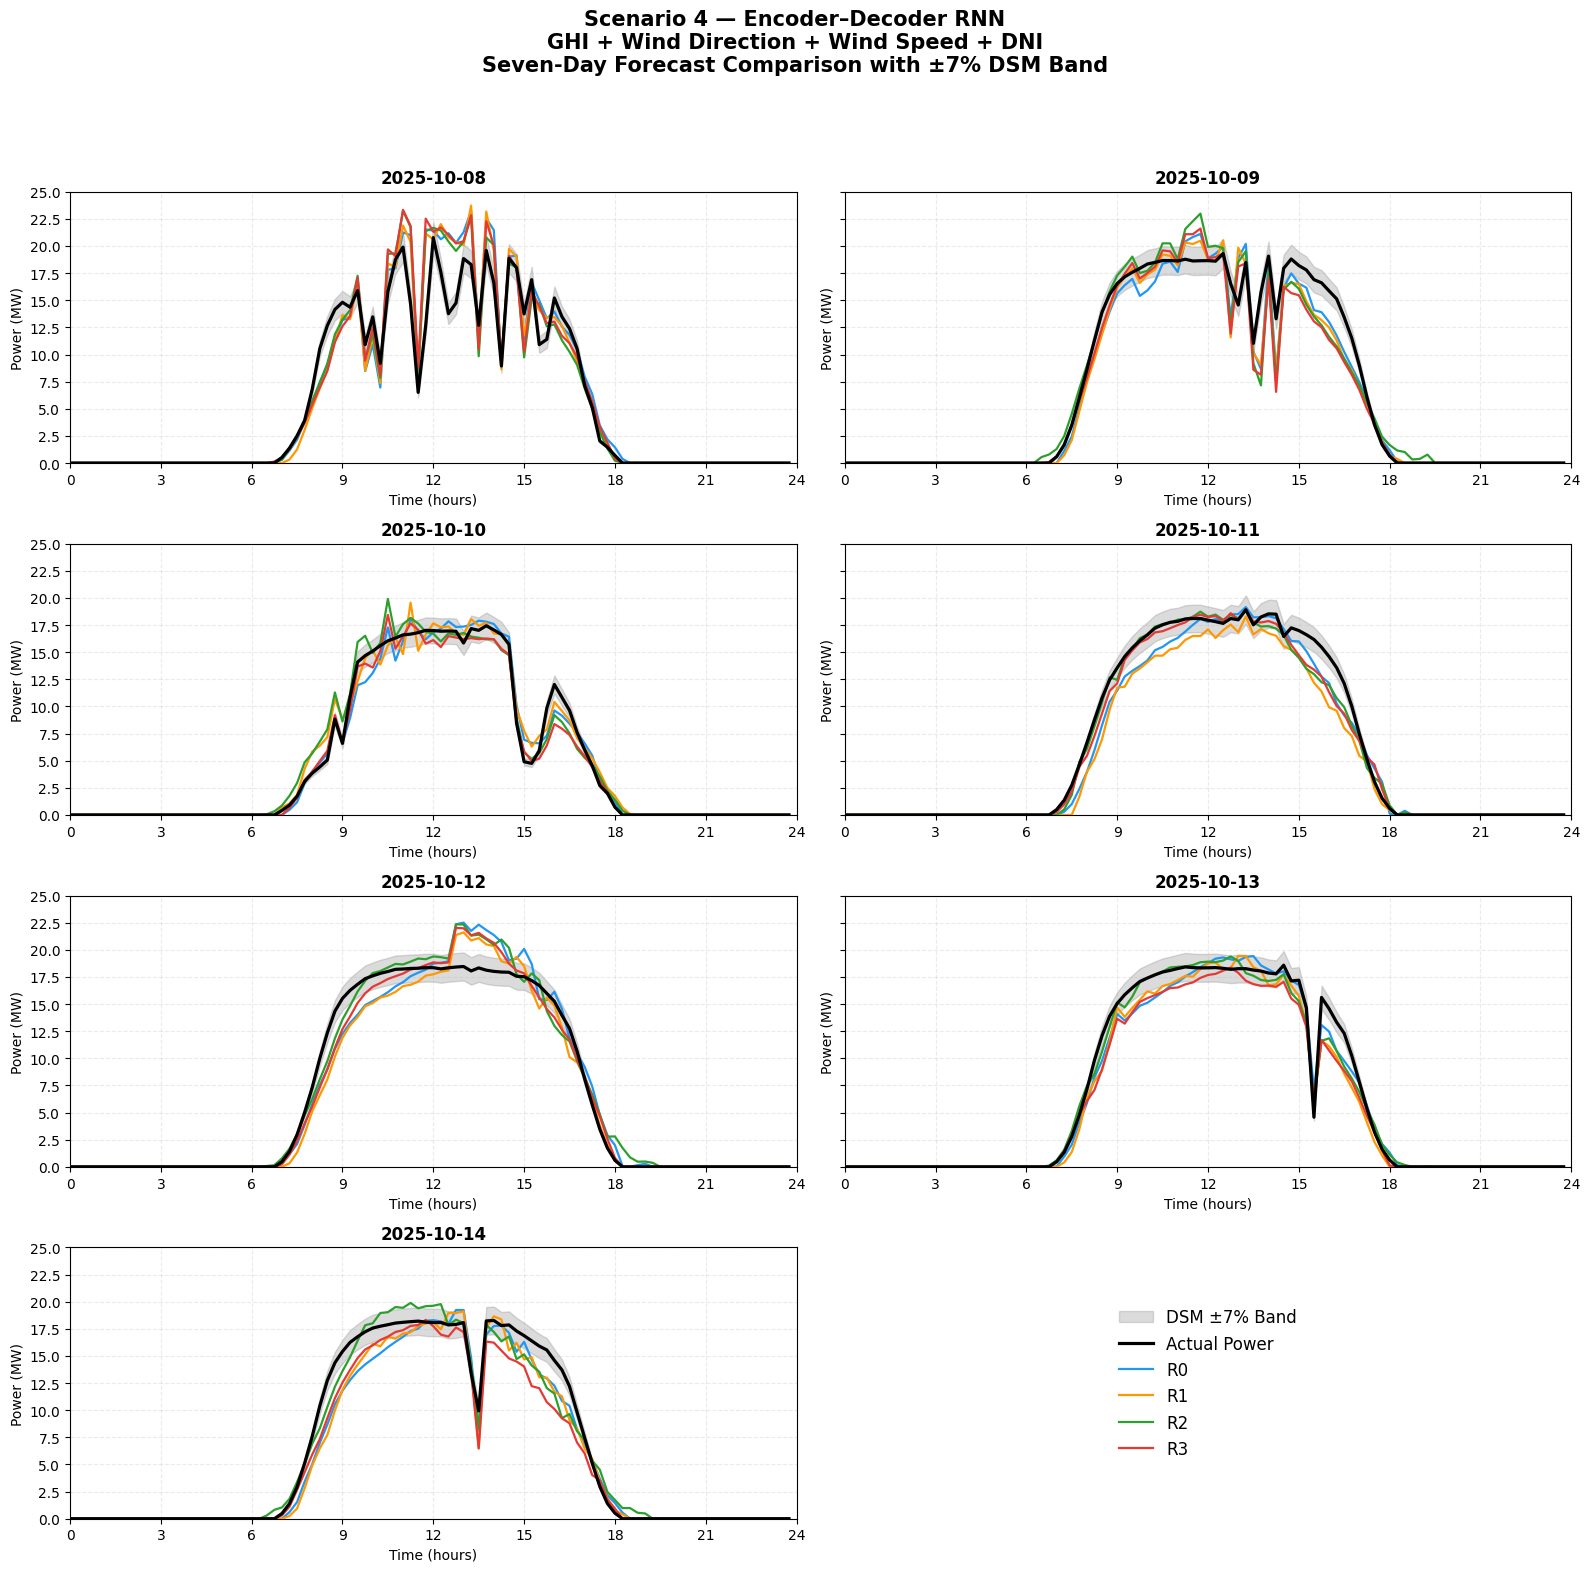

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# ============================================================
# SCENARIO 4 — FINAL TEST EVALUATION
# Encoder–Decoder SimpleRNN | 7 Days | 4 Revisions
# ============================================================

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1

REVISION_ORDER = ["R0", "R1", "R2", "R3"]

COLORS = {
    "R0": "#2196F3",
    "R1": "#FF9800",
    "R2": "#2CA02C",
    "R3": "#E53935",
}

# ============================================================
# 1. GENERATE PREDICTIONS
# ============================================================

predictions_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    verbose=0,
)

# Inverse transform predictions
y_test_pred_raw = scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).reshape(y_test.shape)

# Final postprocessing
y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_blocks] = 0.0

assert np.isfinite(y_test_pred).all()

# ============================================================
# 2. VERIFY TEST DATA
# ============================================================

test_dates_array = np.asarray(dates_test)
test_labels = np.asarray(revision_labels_test)

unique_test_dates = sorted(set(test_dates_array))

assert len(unique_test_dates) == 7, (
    "Expected exactly seven test days."
)

assert y_test_pred.shape == (
    7 * len(REVISION_ORDER),
    TARGET_LENGTH,
)

for day in unique_test_dates:
    for revision in REVISION_ORDER:
        count = np.sum(
            (test_dates_array == day)
            & (test_labels == revision)
        )

        assert count == 1, (
            f"Missing or duplicate sample: {day}, {revision}"
        )

print("=" * 65)
print("SCENARIO 4 — FINAL TEST RESULTS")
print("=" * 65)

print(
    "Forecast dates:",
    ", ".join(map(str, unique_test_dates))
)

print(
    "Test profiles:",
    len(unique_test_dates) * len(REVISION_ORDER)
)

print("Forecast blocks per profile:", TARGET_LENGTH)

# ============================================================
# 3. EVALUATION METRICS
# ============================================================

def calculate_metrics(actual, predicted):

    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()

    error = predicted - actual

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    mbe = np.mean(error)

    # MAPE over active generation blocks only,
    # avoiding division by zero at night.
    active = actual > ACTIVE_THRESHOLD_MW

    mape = (
        np.mean(
            np.abs(error[active] / actual[active])
        ) * 100
        if np.any(active)
        else np.nan
    )

    # DSM ±7% tolerance
    tolerance = BAND_FRACTION * np.abs(actual)

    inside = (
        np.abs(error) <= tolerance + 1e-6
    )

    inside_all = 100 * np.mean(inside)

    inside_active = (
        100 * np.mean(inside[active])
        if np.any(active)
        else np.nan
    )

    return {
        "MAE (MW)": mae,
        "RMSE (MW)": rmse,
        "MAPE (%)": mape,
        "R²": r2,
        "MBE (MW)": mbe,
        "Inside / all": f"{inside.sum()}/{inside.size}",
        "Inside all (%)": inside_all,
        "Inside / active": (
            f"{np.sum(inside & active)}/{np.sum(active)}"
        ),
        "Inside active (%)": inside_active,
    }


rows = []

for revision in ["Overall"] + REVISION_ORDER:

    if revision == "Overall":
        mask = np.ones(
            len(y_test),
            dtype=bool,
        )
    else:
        mask = test_labels == revision

    actual = y_test[mask]
    predicted = y_test_pred[mask]

    metrics = calculate_metrics(
        actual,
        predicted,
    )

    rows.append({
        "Revision": revision,
        **metrics,
    })

test_metrics = pd.DataFrame(rows)

print("\nPERFORMANCE METRICS")
print("-" * 65)
print(
    test_metrics.round(4).to_string(index=False)
)

# ============================================================
# 4. VISUALIZATION — SEVEN TEST DAYS
# ============================================================

hours = np.arange(TARGET_LENGTH) / 4

fig, axes = plt.subplots(
    4,
    2,
    figsize=(16, 16),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()

maximum = max(
    float(
        np.max(
            y_test + BAND_FRACTION * np.abs(y_test)
        )
    ),
    float(np.max(y_test_pred)),
)

y_upper = max(
    20.0,
    np.ceil(maximum / 2.5) * 2.5,
)

for ax, day in zip(axes, unique_test_dates):

    day_indices = np.flatnonzero(
        test_dates_array == day
    )

    actual = y_test[day_indices[0]]

    assert np.allclose(
        y_test[day_indices],
        actual[None, :],
    )

    tolerance = BAND_FRACTION * np.abs(actual)

    lower_band = np.maximum(
        actual - tolerance,
        0.0,
    )

    upper_band = actual + tolerance

    # DSM tolerance band
    ax.fill_between(
        hours,
        lower_band,
        upper_band,
        color="gray",
        alpha=0.28,
        label="DSM ±7% Band",
        zorder=1,
    )

    # Actual generation
    ax.plot(
        hours,
        actual,
        color="black",
        linewidth=2.3,
        label="Actual Power",
        zorder=4,
    )

    # Four revision forecasts
    for revision in REVISION_ORDER:

        index = np.flatnonzero(
            (test_dates_array == day)
            & (test_labels == revision)
        )[0]

        ax.plot(
            hours,
            y_test_pred[index],
            color=COLORS[revision],
            linewidth=1.6,
            label=revision,
            zorder=3,
        )

    ax.set_title(
        str(day),
        fontsize=12,
        fontweight="bold",
    )

    ax.set_xlim(0, 24)
    ax.set_ylim(0, y_upper)

    ax.set_xticks(
        np.arange(0, 25, 3)
    )

    ax.set_yticks(
        np.arange(0, y_upper + 0.1, 2.5)
    )

    ax.set_xlabel("Time (hours)")
    ax.set_ylabel("Power (MW)")

    ax.tick_params(
        axis="x",
        labelbottom=True,
    )

    ax.grid(
        True,
        alpha=0.25,
        linestyle="--",
    )

# Use the empty eighth panel for the legend
axes[-1].axis("off")

handles, labels = axes[0].get_legend_handles_labels()

axes[-1].legend(
    handles,
    labels,
    loc="center",
    fontsize=12,
    frameon=False,
)

fig.suptitle(
    "Scenario 4 — Encoder–Decoder RNN\n"
    "GHI + Wind Direction + Wind Speed + DNI\n"
    "Seven-Day Forecast Comparison with ±7% DSM Band",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.show()

# ============================================================
# 5. OPTIONAL: SAVE FINAL EVALUATION RESULTS
# ============================================================

# Save these if an output directory is already defined.
#
# test_metrics.to_csv(
#     save_dir / "summer_s4_test_metrics.csv",
#     index=False,
# )
#
# np.savez_compressed(
#     save_dir / "summer_s4_test_results.npz",
#     y_actual=y_test,
#     y_pred=y_test_pred,
#     revision_labels=test_labels,
#     dates_test=test_dates_array,
# )


In [17]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEASON = "Summer"
SCENARIO = "S4"
MODEL_NAME = "RNN"

PROJECT_DIR = Path.home() / "Desktop" / "ML" / "Project Fall 2026"

results_dir = PROJECT_DIR / "Notebooks" / "Results" / SEASON
prediction_dir = results_dir / "Predictions"
metrics_dir = results_dir / "Daily_Metrics"

for folder in (results_dir, prediction_dir, metrics_dir):
    folder.mkdir(parents=True, exist_ok=True)

TARGET_LENGTH = 96
ACTIVE_THRESHOLD_MW = 0.1

REVISION_ORDER = ["R0", "R1", "R2", "R3"]

revision_names = {
    "R0": "Rev0",
    "R1": "Rev1",
    "R2": "Rev2",
    "R3": "Rev3",
}

# ============================================================
# 2. AUTOMATICALLY DETECT TEST DATES
# ============================================================

dates = pd.DatetimeIndex(
    pd.to_datetime(dates_test)
).normalize()

raw_labels = np.asarray(
    revision_labels_test
).astype(str)

# Support both R0 and Rev0 naming conventions
label_mapping = {
    "R0": "R0",
    "R1": "R1",
    "R2": "R2",
    "R3": "R3",
    "Rev0": "R0",
    "Rev1": "R1",
    "Rev2": "R2",
    "Rev3": "R3",
}

labels = np.array([
    label_mapping.get(label.strip(), label.strip())
    for label in raw_labels
])

test_days = pd.DatetimeIndex(
    sorted(dates.unique())
)

n_days = len(test_days)
n_samples = len(dates)

print("=" * 65)
print("SUMMER S4 — TEST DATA INFORMATION")
print("=" * 65)

print("\nDetected test dates:")
for day in test_days:
    print(day.strftime("%d-%b-%Y"))

print("\nNumber of test days:", n_days)
print("Number of samples:", n_samples)

# ============================================================
# 3. VALIDATE TEST SAMPLES
# ============================================================

expected = pd.MultiIndex.from_product(
    [test_days, REVISION_ORDER],
    names=["Date", "Revision"],
)

observed = pd.MultiIndex.from_arrays(
    [dates, labels],
    names=["Date", "Revision"],
)

if not observed.sort_values().equals(
    expected.sort_values()
):
    counts = pd.DataFrame({
        "Date": dates,
        "Revision": labels,
    }).groupby(
        ["Date", "Revision"]
    ).size()

    print("\nAvailable date-revision combinations:")
    print(counts.to_string())

    raise ValueError(
        "Test samples do not contain exactly "
        "one R0, R1, R2 and R3 for each test date. "
        "Check dates_test and revision_labels_test."
    )

print("\nSample validation successful.")
print(f"{n_days} days × 4 revisions = {n_samples} profiles")

# ============================================================
# 4. GENERATE PREDICTIONS
# ============================================================

predicted_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    batch_size=16,
    verbose=0,
)

predicted_scaled = np.asarray(predicted_scaled)

y_actual = np.asarray(
    y_test,
    dtype=np.float64,
).copy()

expected_shape = (n_samples, TARGET_LENGTH)

if predicted_scaled.shape != expected_shape:
    raise ValueError(
        f"Prediction shape {predicted_scaled.shape}, "
        f"expected {expected_shape}."
    )

if y_actual.shape != expected_shape:
    raise ValueError(
        f"Actual shape {y_actual.shape}, "
        f"expected {expected_shape}."
    )

# Inverse transformation using target scaler
y_pred_raw = scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).reshape(expected_shape)

if not (
    np.isfinite(y_actual).all()
    and np.isfinite(y_pred_raw).all()
):
    raise ValueError(
        "Actual or predicted power contains nonfinite values."
    )

# ============================================================
# 5. APPLY FINAL POSTPROCESSING
# ============================================================

# Use saved training-derived night mask.
# Supports boolean masks or night-block indices.

if "night_mask" in globals() and night_mask is not None:
    mask_source = np.asarray(night_mask)

elif "night_blocks" in globals():
    mask_source = np.asarray(night_blocks)

else:
    raise ValueError(
        "No night mask found. Load the saved "
        "training-derived night mask first."
    )

if mask_source.dtype == bool:
    final_night_mask = mask_source.copy()

else:
    indices = np.asarray(mask_source, dtype=int)

    if np.any(indices < 0) or np.any(indices >= TARGET_LENGTH):
        raise ValueError("Night-block indices are out of range.")

    final_night_mask = np.zeros(
        TARGET_LENGTH,
        dtype=bool,
    )

    final_night_mask[indices] = True

if final_night_mask.shape != (TARGET_LENGTH,):
    raise ValueError(
        "Expected a night mask of length 96."
    )

# Clip negative power and apply night mask
y_pred = np.maximum(y_pred_raw, 0.0)
y_pred[:, final_night_mask] = 0.0

# Compatibility with earlier notebook cells
y_test_pred_raw = y_pred_raw
y_test_pred = y_pred

# Verify identical actual profiles across revisions
for day in test_days:

    day_actual = y_actual[dates == day]

    if not np.allclose(
        day_actual,
        day_actual[0],
        atol=1e-6,
        rtol=0,
    ):
        raise ValueError(
            f"{day.date()}: actual power differs "
            "across revisions."
        )

print("\nPredictions generated successfully.")
print("Prediction shape:", y_pred.shape)

# ============================================================
# 6. SAVE PREDICTIONS CSV
# ============================================================

block_offsets = pd.to_timedelta(
    15 * np.arange(TARGET_LENGTH),
    unit="min",
)

predictions_df = pd.DataFrame({
    "Revision": np.repeat(
        [revision_names[r] for r in labels],
        TARGET_LENGTH,
    ),
    "Target_Time": (
        dates.repeat(TARGET_LENGTH)
        + np.tile(
            block_offsets.to_numpy(),
            n_samples,
        )
    ),
    "Actual_MW": y_actual.ravel(),
    "Forecast_MW": y_pred.ravel(),
})

predictions_df = predictions_df.sort_values(
    ["Revision", "Target_Time"],
    ignore_index=True,
)

prediction_path = (
    prediction_dir
    / f"{SEASON}_Daily_RNN_{SCENARIO}.csv"
)

results_path = prediction_path

predictions_df.to_csv(
    prediction_path,
    index=False,
    date_format="%Y-%m-%d %H:%M",
)

# ============================================================
# 7. SAVE RAW AND FINAL PREDICTION ARRAYS
# ============================================================

arrays_path = (
    prediction_dir
    / f"{SEASON}_RNN_{SCENARIO}_Test_Results.npz"
)

np.savez_compressed(
    arrays_path,
    y_actual=y_actual,
    y_pred_raw=y_pred_raw,
    y_pred=y_pred,
    revision_labels=labels.astype(str),
    dates_test=dates.strftime(
        "%Y-%m-%d"
    ).to_numpy(dtype=str),
    night_mask=final_night_mask,
)

# ============================================================
# 8. METRIC CALCULATION FUNCTION
# ============================================================

def calculate_metrics(actual, forecast):

    actual = np.asarray(
        actual,
        dtype=np.float64,
    ).ravel()

    forecast = np.asarray(
        forecast,
        dtype=np.float64,
    ).ravel()

    error = forecast - actual

    mae = mean_absolute_error(actual, forecast)

    rmse = np.sqrt(
        mean_squared_error(actual, forecast)
    )

    # MAPE on generating blocks only
    generating = actual > ACTIVE_THRESHOLD_MW

    mape = (
        100 * np.mean(
            np.abs(
                error[generating] / actual[generating]
            )
        )
        if generating.any()
        else np.nan
    )

    r2 = (
        r2_score(actual, forecast)
        if actual.size > 1 and np.var(actual) > 0
        else np.nan
    )

    mbe = np.mean(error)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2,
        "MBE": mbe,
    }

# ============================================================
# 9. CALCULATE DAILY METRICS
# ============================================================

analysis_data = predictions_df.copy()

analysis_data["Date"] = (
    analysis_data["Target_Time"].dt.normalize()
)

daily_rows = []

for (revision, day), group in analysis_data.groupby(
    ["Revision", "Date"],
    sort=True,
):

    if len(group) != TARGET_LENGTH:
        raise ValueError(
            f"{revision}, {day}: expected 96 blocks."
        )

    metrics = calculate_metrics(
        group["Actual_MW"],
        group["Forecast_MW"],
    )

    daily_rows.append({
        "Revision": revision,
        "Date": day,
        **metrics,
    })

daily_metrics = pd.DataFrame(daily_rows)

metric_columns = [
    "MAE",
    "RMSE",
    "MAPE",
    "R2",
    "MBE",
]

# ============================================================
# 10. DAILY METRICS + AVERAGE PER REVISION
# ============================================================

output_rows = []

for revision in revision_names.values():

    revision_daily = daily_metrics.loc[
        daily_metrics["Revision"] == revision
    ].sort_values("Date")

    for _, row in revision_daily.iterrows():

        output_rows.append({
            "Revision": revision,
            "Date": row["Date"].strftime("%d-%b-%Y"),
            **{
                column: row[column]
                for column in metric_columns
            },
        })

    # Arithmetic average of daily metrics
    output_rows.append({
        "Revision": revision,
        "Date": "Average",
        **{
            column: revision_daily[column].mean()
            for column in metric_columns
        },
    })

daily_metrics_with_average = pd.DataFrame(
    output_rows
)

daily_path = (
    metrics_dir
    / f"{SEASON}_Daily_Metrics_RNN_{SCENARIO}.csv"
)

daily_metrics_with_average.to_csv(
    daily_path,
    index=False,
    na_rep="NaN",
)

# ============================================================
# 11. POOLED METRICS — OVERALL AND REVISION-WISE
# ============================================================

pooled_rows = [{
    "Model": MODEL_NAME,
    "Scenario": SCENARIO,
    "Revision": "Overall",
    **calculate_metrics(
        predictions_df["Actual_MW"],
        predictions_df["Forecast_MW"],
    ),
}]

for revision in revision_names.values():

    group = predictions_df.loc[
        predictions_df["Revision"] == revision
    ]

    pooled_rows.append({
        "Model": MODEL_NAME,
        "Scenario": SCENARIO,
        "Revision": revision,
        **calculate_metrics(
            group["Actual_MW"],
            group["Forecast_MW"],
        ),
    })

test_metrics = pd.DataFrame(pooled_rows)

pooled_path = (
    metrics_dir
    / f"{SEASON}_Pooled_Metrics_RNN_{SCENARIO}.csv"
)

test_metrics.to_csv(
    pooled_path,
    index=False,
    na_rep="NaN",
)

# ============================================================
# 12. UPDATE SHARED SINGLE-DAY COMPARISON
# ============================================================

# Prefer June 8 if it exists.
# Otherwise use the first available test day.
preferred_date = pd.Timestamp("2026-06-08")

selected_date = (
    preferred_date
    if preferred_date in test_days
    else test_days[0]
)

comparison_rows = daily_metrics.loc[
    daily_metrics["Date"] == selected_date
].copy()

comparison_rows.insert(
    0,
    "Scenario",
    SCENARIO,
)

comparison_rows.insert(
    0,
    "Model",
    MODEL_NAME,
)

comparison_path = (
    results_dir
    / f"{SEASON}_Daily_Metrics_RNN_"
      f"{selected_date:%Y-%m-%d}.csv"
)

if comparison_path.exists():

    previous = pd.read_csv(comparison_path)

    expected_columns = list(comparison_rows.columns)

    if set(previous.columns) != set(expected_columns):
        raise ValueError(
            "Unexpected columns in existing "
            f"comparison CSV: {comparison_path.name}"
        )

    previous = previous[expected_columns]

    previous["Date"] = pd.to_datetime(
        previous["Date"],
        format="mixed",
        dayfirst=True,
        errors="raise",
    ).dt.normalize()

    # Prevent mixing different dates in one comparison
    if not (previous["Date"] == selected_date).all():
        raise ValueError(
            "Existing comparison CSV contains "
            "a different date."
        )

    combined = pd.concat(
        [previous, comparison_rows],
        ignore_index=True,
    )

else:
    combined = comparison_rows.copy()

# Replace only matching rows; preserve other scenarios
combined = (
    combined
    .drop_duplicates(
        ["Model", "Scenario", "Revision", "Date"],
        keep="last",
    )
    .sort_values(
        ["Date", "Model", "Scenario", "Revision"],
        ignore_index=True,
    )
)

combined["Date"] = combined["Date"].dt.strftime(
    "%d-%b-%Y"
)

try:
    combined.to_csv(
        comparison_path,
        index=False,
        na_rep="NaN",
    )

    print(
        "\nComparison file updated:",
        comparison_path,
    )

except PermissionError:

    fallback_path = comparison_path.with_name(
        comparison_path.stem + "_updated.csv"
    )

    combined.to_csv(
        fallback_path,
        index=False,
        na_rep="NaN",
    )

    print(
        "\nComparison file was locked."
    )
    print("Updated copy:", fallback_path)

# ============================================================
# 13. FINAL RESULTS SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("SUMMER S4 — RESULTS EXPORT COMPLETED")
print("=" * 70)

print(f"\nSeason          : {SEASON}")
print(f"Scenario        : {SCENARIO}")
print(f"Model           : {MODEL_NAME}")
print(f"Test days       : {n_days}")
print(f"Forecasts       : {n_samples}")
print(f"Blocks/profile  : {TARGET_LENGTH}")
print(f"Prediction rows : {len(predictions_df):,}")

print("\nSaved files:")
print("Predictions       :", prediction_path)
print("Prediction arrays :", arrays_path)
print("Daily metrics     :", daily_path)
print("Pooled metrics    :", pooled_path)

print("\nPOOLED TEST METRICS")
print("-" * 70)

print(
    test_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nDAILY METRICS WITH AVERAGES")
print("-" * 70)

print(
    daily_metrics_with_average.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nExport complete.")


SUMMER S4 — TEST DATA INFORMATION

Detected test dates:
08-Oct-2025
09-Oct-2025
10-Oct-2025
11-Oct-2025
12-Oct-2025
13-Oct-2025
14-Oct-2025

Number of test days: 7
Number of samples: 28

Sample validation successful.
7 days × 4 revisions = 28 profiles

Predictions generated successfully.
Prediction shape: (28, 96)

Comparison file updated: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Summer_Daily_Metrics_RNN_2025-10-08.csv

SUMMER S4 — RESULTS EXPORT COMPLETED

Season          : Summer
Scenario        : S4
Model           : RNN
Test days       : 7
Forecasts       : 28
Blocks/profile  : 96
Prediction rows : 2,688

Saved files:
Predictions       : C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_Daily_RNN_S4.csv
Prediction arrays : C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_RNN_S4_Test_Results.npz
Daily metrics     : C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Sum

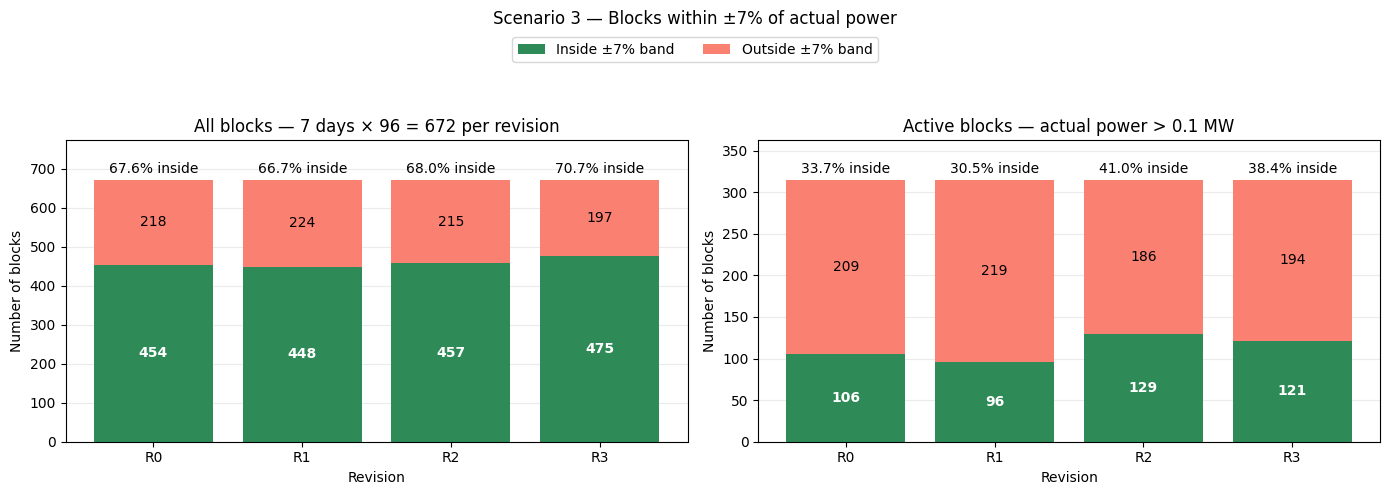

In [18]:
# Uses existing y_test, y_test_pred, and test_labels.
revisions = list(REVISION_LENGTHS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, active_only in zip(axes, [False, True]):
    inside_counts = []
    outside_counts = []

    for revision in revisions:
        revision_mask = test_labels == revision

        actual = y_test[revision_mask].ravel()
        predicted = y_test_pred[revision_mask].ravel()

        eligible = (
            actual > ACTIVE_THRESHOLD_MW
            if active_only
            else np.ones(actual.shape, dtype=bool)
        )

        inside = (
            np.abs(predicted - actual)
            <= BAND_FRACTION * np.abs(actual) + 1e-6
        )

        inside_counts.append(int(np.sum(inside & eligible)))
        outside_counts.append(int(np.sum(~inside & eligible)))

    inside_counts = np.asarray(inside_counts)
    outside_counts = np.asarray(outside_counts)
    totals = inside_counts + outside_counts

    ax.bar(
        revisions, inside_counts,
        color="seagreen", label="Inside ±7% band",
    )
    ax.bar(
        revisions, outside_counts,
        bottom=inside_counts,
        color="salmon", label="Outside ±7% band",
    )

    for i, (inside, outside, total) in enumerate(
        zip(inside_counts, outside_counts, totals)
    ):
        if inside:
            ax.text(
                i, inside / 2, str(inside),
                ha="center", va="center", color="white",
                fontweight="bold",
            )
        if outside:
            ax.text(
                i, inside + outside / 2, str(outside),
                ha="center", va="center",
            )
        if total:
            ax.text(
                i, total + max(totals.max(), 1) * 0.025,
                f"{100 * inside / total:.1f}% inside",
                ha="center", fontsize=10,
            )

    ax.set_title(
        "Active blocks — actual power > 0.1 MW"
        if active_only else
        "All blocks — 7 days × 96 = 672 per revision"
    )
    ax.set_xlabel("Revision")
    ax.set_ylabel("Number of blocks")
    ax.set_ylim(0, max(int(totals.max()), 1) * 1.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.94), ncol=2,
)
fig.suptitle("Scenario 3 — Blocks within ±7% of actual power")
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

In [ ]:
# SUMMER: DSM + DAILY METRICS + JUNE 8 COMPARISON FOR S1–S4
# Uses saved prediction CSVs only. No model loading or retraining.

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score


# 1. Configuration
SEASON = "Summer"
SCENARIOS = ("S1", "S2", "S3", "S4")
REVISIONS = ["Rev0", "Rev1", "Rev2", "Rev3"]

results_dir = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
    r"\Notebooks\Results\Summer"
)
prediction_dir = results_dir / "Predictions"
dsm_dir = results_dir / "DSM"
metrics_dir = results_dir / "Daily_Metrics"

test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")
selected_day = pd.Timestamp("2026-06-08")

expected_times = pd.date_range(
    test_days[0], periods=7 * 96, freq="15min"
)
expected_index = pd.MultiIndex.from_product(
    [REVISIONS, expected_times],
    names=["Revision", "Target_Time"],
)

prediction_columns = [
    "Revision", "Target_Time", "Actual_MW", "Forecast_MW"
]
metric_columns = ["MAE", "RMSE", "MAPE", "R2", "MBE"]
combined_columns = [
    "Model", "Scenario", "Revision", "Date", *metric_columns
]

AC_CAPACITY_MW = 21.5
MW_TO_KWH = 1000 * 0.25

threshold_7 = 0.07 * AC_CAPACITY_MW
threshold_15 = 0.15 * AC_CAPACITY_MW
threshold_23 = 0.23 * AC_CAPACITY_MW


# 2. Metrics using the same definitions as winter.
def calculate_metrics(data):
    actual = data["Actual_MW"].to_numpy(dtype=np.float64)
    forecast = data["Forecast_MW"].to_numpy(dtype=np.float64)

    error = forecast - actual
    positive_actual = actual > 0

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": (
            100 * np.mean(
                np.abs(error[positive_actual] / actual[positive_actual])
            )
            if positive_actual.any()
            else np.nan
        ),
        "R2": (
            r2_score(actual, forecast)
            if np.var(actual) > 0
            else np.nan
        ),
        "MBE": np.mean(error),
    }


# 3. Validate all four prediction files before preparing outputs.
prediction_tables = {}
reference_actual = None

for scenario in SCENARIOS:
    input_path = prediction_dir / f"{SEASON}_Daily_RNN_{scenario}.csv"

    if not input_path.is_file():
        raise FileNotFoundError(f"Prediction file missing: {input_path}")

    data = pd.read_csv(input_path)

    missing = set(prediction_columns) - set(data.columns)
    if missing:
        raise ValueError(f"{scenario}: missing columns {sorted(missing)}.")

    data = data.loc[:, prediction_columns].copy()
    data["Target_Time"] = pd.to_datetime(
        data["Target_Time"], errors="raise"
    )

    observed_index = pd.MultiIndex.from_frame(
        data[["Revision", "Target_Time"]]
    )
    if not observed_index.sort_values().equals(expected_index.sort_values()):
        raise ValueError(
            f"{scenario}: expected exactly 2,688 rows, with one forecast "
            "per revision and 15-minute timestamp for June 8–14."
        )

    for column in ("Actual_MW", "Forecast_MW"):
        data[column] = pd.to_numeric(data[column], errors="raise")

    if not np.isfinite(
        data[["Actual_MW", "Forecast_MW"]].to_numpy()
    ).all():
        raise ValueError(f"{scenario}: missing or infinite power values.")

    actual_by_revision = data.pivot(
        index="Target_Time",
        columns="Revision",
        values="Actual_MW",
    ).loc[expected_times, REVISIONS]

    actual_curve = actual_by_revision["Rev0"].to_numpy()

    if not np.allclose(
        actual_by_revision.to_numpy(),
        actual_curve[:, None],
        atol=1e-6,
        rtol=0,
    ):
        raise ValueError(f"{scenario}: actual power differs across revisions.")

    if reference_actual is None:
        reference_actual = actual_curve.copy()
    elif not np.allclose(
        actual_curve, reference_actual, atol=1e-6, rtol=0
    ):
        raise ValueError(f"{scenario}: actual power differs across scenarios.")

    prediction_tables[scenario] = data.sort_values(
        ["Revision", "Target_Time"], ignore_index=True
    )


# 4. Prepare DSM and daily-metric tables.
dsm_outputs = {}
daily_outputs = {}
comparison_rows = []

for scenario, predictions in prediction_tables.items():
    # DSM: absolute error and progressive charges from the supplied formula.
    dsm = predictions.copy()
    error = np.abs(dsm["Actual_MW"] - dsm["Forecast_MW"])

    dsm["Error_MW"] = error
    dsm["Deviation_Percent"] = error / AC_CAPACITY_MW * 100
    dsm["Deviation_Energy_kWh"] = error * MW_TO_KWH

    no_generation = (
        dsm["Actual_MW"].eq(0) & dsm["Forecast_MW"].eq(0)
    )

    dsm["Violation_Slab"] = np.select(
        [
            no_generation,
            error <= threshold_7,
            error <= threshold_15,
            error <= threshold_23,
        ],
        ["No Generation", "<=7%", "7-15%", "15-23%"],
        default=">23%",
    )

    energy_7_to_15 = np.clip(
        error - threshold_7,
        0,
        threshold_15 - threshold_7,
    ) * MW_TO_KWH

    energy_15_to_23 = np.clip(
        error - threshold_15,
        0,
        threshold_23 - threshold_15,
    ) * MW_TO_KWH

    energy_above_23 = np.maximum(
        error - threshold_23, 0
    ) * MW_TO_KWH

    dsm["DSM_Charge_Rs"] = (
        0.25 * energy_7_to_15
        + 0.50 * energy_15_to_23
        + 0.75 * energy_above_23
    )

    dsm_outputs[scenario] = dsm

    # Daily metrics: seven dates followed by Average for each revision.
    data = predictions.copy()
    data["Date"] = data["Target_Time"].dt.normalize()
    rows = []

    for revision in REVISIONS:
        daily_rows = []

        for day in test_days:
            day_data = data.loc[
                data["Revision"].eq(revision)
                & data["Date"].eq(day)
            ].sort_values("Target_Time")

            if len(day_data) != 96:
                raise ValueError(
                    f"{scenario}, {revision}, {day.date()}: expected 96 blocks."
                )

            metrics = calculate_metrics(day_data)

            daily_rows.append({
                "Revision": revision,
                "Date": day.strftime("%d-%b-%Y"),
                **metrics,
            })

            if day == selected_day:
                comparison_rows.append({
                    "Model": "RNN",
                    "Scenario": scenario,
                    "Revision": revision,
                    "Date": day,
                    **metrics,
                })

        rows.extend(daily_rows)

        # Arithmetic mean of seven daily metrics, matching winter.
        # Any undefined daily metric keeps its Average undefined.
        averages = (
            pd.DataFrame(daily_rows)[metric_columns]
            .mean(skipna=False)
            .to_dict()
        )

        rows.append({
            "Revision": revision,
            "Date": "Average",
            **averages,
        })

    daily_outputs[scenario] = pd.DataFrame(
        rows,
        columns=["Revision", "Date", *metric_columns],
    )


# 5. Prepare the shared June 8 comparison, preserving other existing rows.
combined_path = (
    results_dir
    / f"{SEASON}_Daily_Metrics_RNN_{selected_day:%Y-%m-%d}.csv"
)
new_rows = pd.DataFrame(comparison_rows, columns=combined_columns)

if combined_path.exists():
    existing = pd.read_csv(combined_path)

    if list(existing.columns) != combined_columns:
        raise ValueError("Existing comparison CSV has unexpected columns.")

    existing["Date"] = existing["Date"].map(
        lambda value: pd.to_datetime(
            value, dayfirst=True, errors="raise"
        )
    ).dt.normalize()

    combined = pd.concat([existing, new_rows], ignore_index=True)
else:
    combined = new_rows.copy()

combined = (
    combined
    .drop_duplicates(
        subset=["Model", "Scenario", "Revision", "Date"],
        keep="last",
    )
    .sort_values(
        ["Date", "Model", "Scenario", "Revision"],
        ignore_index=True,
    )
)
combined["Date"] = combined["Date"].dt.strftime("%d-%b-%y")


# 6. Save all nine analysis CSVs.
for folder in (results_dir, dsm_dir, metrics_dir):
    folder.mkdir(parents=True, exist_ok=True)

saved_paths = []


def save_csv(table, path, **kwargs):
    try:
        table.to_csv(path, index=False, **kwargs)
        saved_path = path
    except PermissionError:
        saved_path = path.with_name(
            f"{path.stem}_updated_{pd.Timestamp.now():%Y%m%d_%H%M%S_%f}.csv"
        )
        table.to_csv(saved_path, index=False, **kwargs)
        print(f"Original file locked: {path.name}")

    saved_paths.append(saved_path)
    print(f"Saved {len(table):,} rows: {saved_path}")


for scenario in SCENARIOS:
    save_csv(
        dsm_outputs[scenario],
        dsm_dir / f"{SEASON}_Daily_RNN_{scenario}_DSM.csv",
        date_format="%Y-%m-%d %H:%M",
    )

    save_csv(
        daily_outputs[scenario],
        metrics_dir / f"{SEASON}_Daily_Metrics_RNN_{scenario}.csv",
        na_rep="NaN",
    )

save_csv(combined, combined_path, na_rep="NaN")

print("\nJune 8 comparison:")
print(combined.to_string(index=False))

print(f"\nSaved {len(saved_paths)} analysis files:")
print("4 DSM files: 2,688 rows each")
print("4 daily-metric files: 32 rows each")
print("1 shared June 8 comparison file")
print("Prediction CSVs were not modified. No retraining.")


S1 test dates:
['08-Jun-2026', '09-Jun-2026', '10-Jun-2026', '11-Jun-2026', '12-Jun-2026', '13-Jun-2026', '14-Jun-2026']
S1: validated 2,688 predictions.

S2 test dates:
['08-Jun-2026', '09-Jun-2026', '10-Jun-2026', '11-Jun-2026', '12-Jun-2026', '13-Jun-2026', '14-Jun-2026']
S2: validated 2,688 predictions.

S3 test dates:
['08-Jun-2026', '09-Jun-2026', '10-Jun-2026', '11-Jun-2026', '12-Jun-2026', '13-Jun-2026', '14-Jun-2026']
S3: validated 2,688 predictions.

S4 test dates:
['08-Oct-2025', '09-Oct-2025', '10-Oct-2025', '11-Oct-2025', '12-Oct-2025', '13-Oct-2025', '14-Oct-2025']


ValueError: S4: test dates differ from S1.
S1: ['2026-06-08', '2026-06-09', '2026-06-10', '2026-06-11', '2026-06-12', '2026-06-13', '2026-06-14']
S4: ['2025-10-08', '2025-10-09', '2025-10-10', '2025-10-11', '2025-10-12', '2025-10-13', '2025-10-14']
Use predictions for the same dates before comparing scenarios.